<a href="https://colab.research.google.com/github/nour2344/RoadAnomaly-DeepLearning/blob/main/notebooks/04_unet_segmentation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# RoadAnomaly — U-Net Segmentation

## 1. Chargement des données

Nous entraînons un modèle U-Net pour la segmentation sémantique des anomalies routières.

Contrairement au CNN Baseline, U-Net utilise des skip connections pour mieux conserver les détails des obstacles.

Nous réutilisons les mêmes ensembles Train, Validation et Test pour comparer les modèles dans les mêmes conditions.

In [1]:
from google.colab import drive
from pathlib import Path
import pandas as pd
import torch

drive.mount("/content/drive")

PROJECT_DIR = Path("/content/drive/MyDrive/deep learning P")
SPLIT_PATH = PROJECT_DIR / "split_manifest.csv"

df = pd.read_csv(SPLIT_PATH)

train_df = df[df["split"] == "train"].reset_index(drop=True)
val_df = df[df["split"] == "validation"].reset_index(drop=True)
test_df = df[df["split"] == "test"].reset_index(drop=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

assert len(train_df) == 42
assert len(val_df) == 9
assert len(test_df) == 9

print("Train :", len(train_df))
print("Validation :", len(val_df))
print("Test :", len(test_df))
print("Device :", device)

Mounted at /content/drive
Train : 42
Validation : 9
Test : 9
Device : cuda


## 2. Préparation des données

Nous réutilisons les mêmes images, masques, transformations et DataLoaders que pour le CNN Baseline.

Cela garantit que la comparaison entre les modèles repose sur les mêmes données.

In [2]:
import numpy as np
from PIL import Image, ImageOps
from torch.utils.data import Dataset, DataLoader

IMG_SIZE = (256, 256)

def preprocess_image(path):
    image = Image.open(path).convert("RGB")
    image = ImageOps.pad(
        image, IMG_SIZE,
        method=Image.Resampling.BILINEAR,
        color=(0, 0, 0)
    )
    return np.asarray(image, dtype=np.float32) / 255.0

def preprocess_mask(path):
    mask = Image.open(path).convert("L")
    mask = ImageOps.pad(
        mask, IMG_SIZE,
        method=Image.Resampling.NEAREST,
        color=0
    )
    return (np.asarray(mask) == 2).astype(np.float32)

def augment_image_mask(image, mask, rng):
    if rng.random() < 0.5:
        image = np.flip(image, axis=1).copy()
        mask = np.flip(mask, axis=1).copy()

    image = np.clip(image * rng.uniform(0.8, 1.2), 0, 1)
    mean = image.mean(axis=(0, 1), keepdims=True)
    image = np.clip(
        (image - mean) * rng.uniform(0.8, 1.2) + mean, 0, 1
    )

    return image.astype(np.float32), mask

class RoadAnomalyDataset(Dataset):
    def __init__(self, dataframe, augment=False):
        self.data = dataframe.reset_index(drop=True)
        self.augment = augment
        self.rng = np.random.default_rng(42)

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        row = self.data.iloc[idx]

        image = preprocess_image(row["image"])
        mask = preprocess_mask(row["mask"])

        if self.augment:
            image, mask = augment_image_mask(image, mask, self.rng)

        image = torch.from_numpy(
            np.ascontiguousarray(image.transpose(2, 0, 1))
        ).float()

        mask = torch.from_numpy(
            np.ascontiguousarray(mask[None, :, :])
        ).float()

        return image, mask

train_loader = DataLoader(
    RoadAnomalyDataset(train_df, augment=True),
    batch_size=4, shuffle=True, num_workers=0
)

val_loader = DataLoader(
    RoadAnomalyDataset(val_df),
    batch_size=4, shuffle=False, num_workers=0
)

test_loader = DataLoader(
    RoadAnomalyDataset(test_df),
    batch_size=4, shuffle=False, num_workers=0
)

images, masks = next(iter(train_loader))

print("Images :", images.shape)
print("Masques :", masks.shape)
print("Device :", device)

Images : torch.Size([4, 3, 256, 256])
Masques : torch.Size([4, 1, 256, 256])
Device : cuda


## 3. Construction du modèle U-Net

Nous utilisons U-Net pour segmenter les anomalies routières.

- **Encodeur :** extrait les caractéristiques des images.
- **Décodeur :** reconstruit le masque à la résolution d'origine.
- **Skip connections :** transmettent les détails de l'encodeur au décodeur.

Le modèle produit un score pour chaque pixel, afin de distinguer les zones normales des anomalies.

In [3]:
import torch
import torch.nn as nn


# Deux convolutions successives
class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.layers = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, 3, padding=1),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.layers(x)


class UNet(nn.Module):
    def __init__(self):
        super().__init__()

        self.pool = nn.MaxPool2d(2)

        # Encodeur
        self.enc1 = DoubleConv(3, 16)
        self.enc2 = DoubleConv(16, 32)
        self.enc3 = DoubleConv(32, 64)

        # Partie centrale
        self.bottleneck = DoubleConv(64, 128)

        # Décodeur
        self.up3 = nn.ConvTranspose2d(128, 64, 2, stride=2)
        self.dec3 = DoubleConv(128, 64)

        self.up2 = nn.ConvTranspose2d(64, 32, 2, stride=2)
        self.dec2 = DoubleConv(64, 32)

        self.up1 = nn.ConvTranspose2d(32, 16, 2, stride=2)
        self.dec1 = DoubleConv(32, 16)

        # Un score par pixel
        self.output = nn.Conv2d(16, 1, kernel_size=1)

    def forward(self, x):
        # Encodeur
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))

        # Partie centrale
        b = self.bottleneck(self.pool(e3))

        # Décodeur avec skip connections
        d3 = self.up3(b)
        d3 = self.dec3(torch.cat([d3, e3], dim=1))

        d2 = self.up2(d3)
        d2 = self.dec2(torch.cat([d2, e2], dim=1))

        d1 = self.up1(d2)
        d1 = self.dec1(torch.cat([d1, e1], dim=1))

        return self.output(d1)


# Créer U-Net sur le GPU
model = UNet().to(device)

# Vérification des dimensions
images, masks = next(iter(train_loader))

with torch.no_grad():
    outputs = model(images.to(device))

print("Entrée :", images.shape)
print("Sortie :", outputs.shape)
print("Masques réels :", masks.shape)
print("Nombre de paramètres :",
      sum(p.numel() for p in model.parameters()))

Entrée : torch.Size([4, 3, 256, 256])
Sortie : torch.Size([4, 1, 256, 256])
Masques réels : torch.Size([4, 1, 256, 256])
Nombre de paramètres : 482033


## 4. Fonction de perte et optimiseur

Nous utilisons la même configuration que pour le CNN Baseline :

- **BCE Loss :** mesure les erreurs de classification des pixels.
- **Dice Loss :** aide à segmenter les anomalies malgré le déséquilibre des classes.
- **Adam :** optimise les paramètres du modèle avec un learning rate de 0.001.

La perte finale combine BCE et Dice avec un poids de 0.5 chacune.

In [4]:
import torch
import torch.nn as nn

# BCE Loss
bce_loss = nn.BCEWithLogitsLoss()

# Dice Loss
def dice_loss(logits, targets, smooth=1.0):
    probs = torch.sigmoid(logits)

    intersection = (probs * targets).sum(dim=(1, 2, 3))
    union = probs.sum(dim=(1, 2, 3)) + targets.sum(dim=(1, 2, 3))

    dice = (2 * intersection + smooth) / (union + smooth)

    return 1 - dice.mean()


# Combinaison BCE + Dice
def combined_loss(logits, targets):
    bce = bce_loss(logits, targets)
    dice = dice_loss(logits, targets)

    return 0.5 * bce + 0.5 * dice


# Optimiseur Adam
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

# Vérification sur un batch
images, masks = next(iter(train_loader))

images = images.to(device)
masks = masks.to(device)

outputs = model(images)
loss = combined_loss(outputs, masks)

print("BCE Loss :", round(bce_loss(outputs, masks).item(), 4))
print("Dice Loss :", round(dice_loss(outputs, masks).item(), 4))
print("Combined Loss :", round(loss.item(), 4))
print("Optimizer : Adam")
print("Learning rate :", optimizer.param_groups[0]["lr"])

BCE Loss : 0.7382
Dice Loss : 0.8938
Combined Loss : 0.816
Optimizer : Adam
Learning rate : 0.001


## 5. Entraînement et validation de U-Net

Nous entraînons U-Net sur les 42 images d'entraînement et suivons sa perte sur les 9 images de validation.

- **Epochs :** maximum 30.
- **Batch size :** 4.
- **Early Stopping :** arrêt après 6 époques sans amélioration.
- **Checkpoint :** sauvegarde du modèle ayant la meilleure Validation Loss.

Nous utilisons les mêmes paramètres que pour le CNN Baseline.

In [5]:
from pathlib import Path
import torch

EPOCHS = 30
PATIENCE = 6

best_val_loss = float("inf")
patience_counter = 0

train_losses = []
val_losses = []

# Dossier de sauvegarde
MODEL_DIR = PROJECT_DIR / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

MODEL_PATH = MODEL_DIR / "unet_best.pth"

for epoch in range(EPOCHS):

    # Entraînement
    model.train()
    train_loss = 0.0

    for images, masks in train_loader:
        images = images.to(device)
        masks = masks.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = combined_loss(outputs, masks)

        loss.backward()
        optimizer.step()

        train_loss += loss.item() * images.size(0)

    train_loss /= len(train_loader.dataset)

    # Validation
    model.eval()
    val_loss = 0.0

    with torch.no_grad():
        for images, masks in val_loader:
            images = images.to(device)
            masks = masks.to(device)

            outputs = model(images)
            loss = combined_loss(outputs, masks)

            val_loss += loss.item() * images.size(0)

    val_loss /= len(val_loader.dataset)

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    print(
        f"Epoch {epoch + 1:02d}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f}"
    )

    # Sauvegarder le meilleur modèle
    if val_loss < best_val_loss - 1e-4:
        best_val_loss = val_loss
        patience_counter = 0

        torch.save(model.state_dict(), MODEL_PATH)

    else:
        patience_counter += 1

    # Early Stopping
    if patience_counter >= PATIENCE:
        print("\nEarly Stopping activated.")
        break

print("\nTraining completed!")
print("Best Validation Loss :", round(best_val_loss, 4))
print("Model saved at :", MODEL_PATH)

Epoch 01/30 | Train Loss: 0.7598 | Val Loss: 0.6334
Epoch 02/30 | Train Loss: 0.6320 | Val Loss: 0.5930
Epoch 03/30 | Train Loss: 0.6021 | Val Loss: 0.5739
Epoch 04/30 | Train Loss: 0.5751 | Val Loss: 0.5532
Epoch 05/30 | Train Loss: 0.5668 | Val Loss: 0.5433
Epoch 06/30 | Train Loss: 0.5542 | Val Loss: 0.5335
Epoch 07/30 | Train Loss: 0.5404 | Val Loss: 0.5273
Epoch 08/30 | Train Loss: 0.5388 | Val Loss: 0.5129
Epoch 09/30 | Train Loss: 0.5274 | Val Loss: 0.5075
Epoch 10/30 | Train Loss: 0.5213 | Val Loss: 0.5010
Epoch 11/30 | Train Loss: 0.5274 | Val Loss: 0.5021
Epoch 12/30 | Train Loss: 0.5221 | Val Loss: 0.4927
Epoch 13/30 | Train Loss: 0.5168 | Val Loss: 0.5146
Epoch 14/30 | Train Loss: 0.5195 | Val Loss: 0.5010
Epoch 15/30 | Train Loss: 0.5102 | Val Loss: 0.4858
Epoch 16/30 | Train Loss: 0.5085 | Val Loss: 0.4749
Epoch 17/30 | Train Loss: 0.4940 | Val Loss: 0.4747
Epoch 18/30 | Train Loss: 0.4949 | Val Loss: 0.4615
Epoch 19/30 | Train Loss: 0.4896 | Val Loss: 0.4509
Epoch 20/30 

## 6. Analyse des courbes d'apprentissage

Nous visualisons les pertes d'entraînement et de validation pour observer l'évolution de U-Net et repérer un éventuel surapprentissage.

La meilleure Validation Loss est de 0.4030, obtenue à l'époque 29.

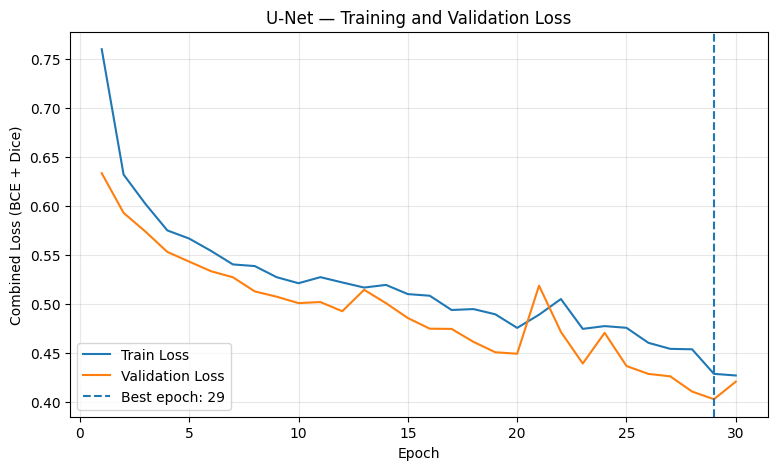

Best epoch : 29
Best Validation Loss : 0.403


In [6]:
import matplotlib.pyplot as plt
import numpy as np

epochs = np.arange(1, len(train_losses) + 1)
best_epoch = int(np.argmin(val_losses)) + 1

plt.figure(figsize=(9, 5))

plt.plot(epochs, train_losses, label="Train Loss")
plt.plot(epochs, val_losses, label="Validation Loss")

plt.axvline(
    best_epoch,
    linestyle="--",
    label=f"Best epoch: {best_epoch}"
)

plt.xlabel("Epoch")
plt.ylabel("Combined Loss (BCE + Dice)")
plt.title("U-Net — Training and Validation Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print("Best epoch :", best_epoch)
print("Best Validation Loss :", round(min(val_losses), 4))

## 7. Évaluation de U-Net

Nous évaluons le meilleur modèle U-Net sur les 9 images de test avec quatre métriques : IoU, Dice, Precision et Recall.

Nous utilisons le même seuil de 0.5 et la même méthode de calcul que pour le CNN Baseline afin de comparer les résultats.

In [7]:
import torch

# Charger le meilleur U-Net
model.load_state_dict(
    torch.load(MODEL_PATH, map_location=device, weights_only=True)
)
model.eval()

TP = FP = FN = 0

with torch.no_grad():
    for images, masks in test_loader:
        images = images.to(device)
        masks = masks.to(device)

        logits = model(images)
        preds = torch.sigmoid(logits) >= 0.5
        targets = masks >= 0.5

        TP += (preds & targets).sum().item()
        FP += (preds & ~targets).sum().item()
        FN += (~preds & targets).sum().item()

eps = 1e-7

iou = TP / (TP + FP + FN + eps)
dice = 2 * TP / (2 * TP + FP + FN + eps)
precision = TP / (TP + FP + eps)
recall = TP / (TP + FN + eps)

print("U-Net — Test Results")
print(f"IoU       : {iou:.4f}")
print(f"Dice      : {dice:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")

U-Net — Test Results
IoU       : 0.2707
Dice      : 0.4260
Precision : 0.3582
Recall    : 0.5257


## 8. Visualisation des prédictions

Nous comparons les masques prédits par U-Net aux masques réels pour observer les anomalies détectées, les anomalies manquées et les faux positifs.

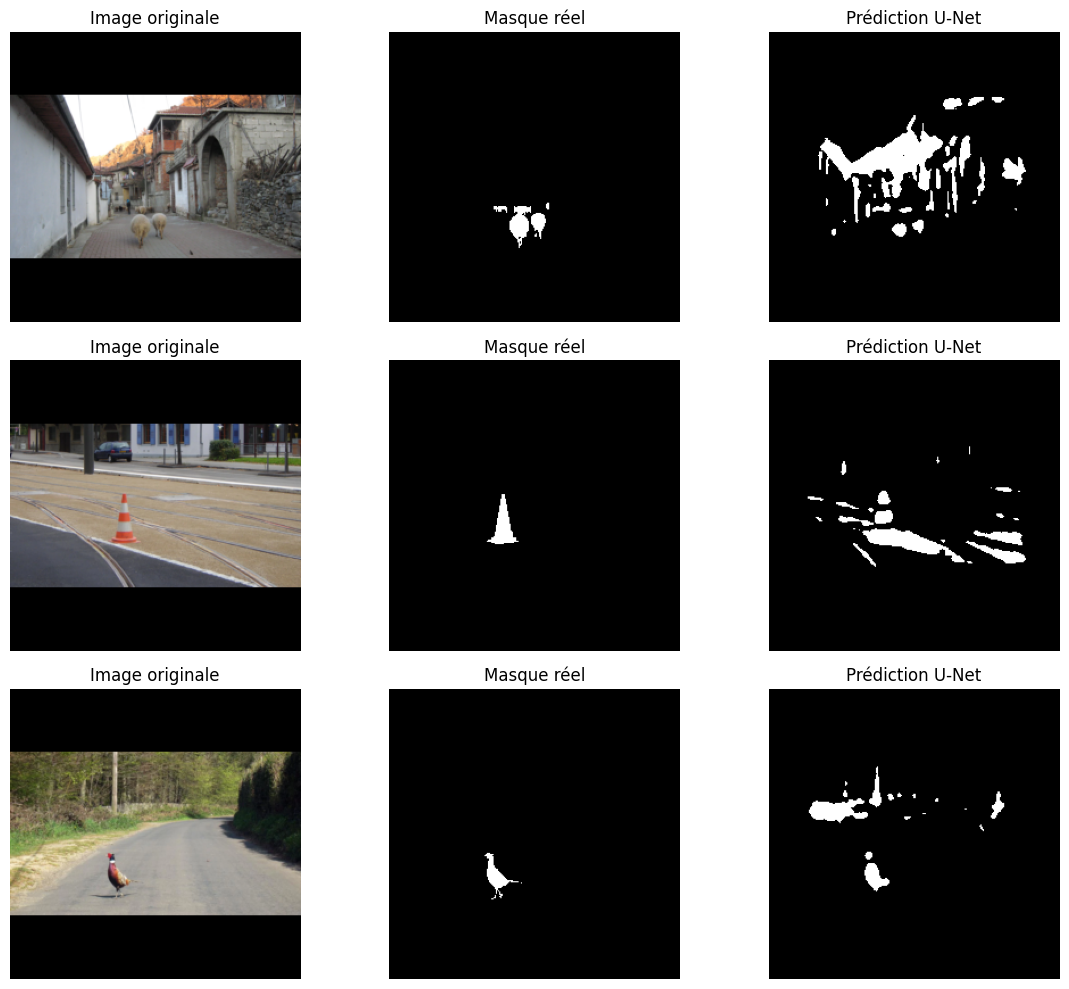

In [8]:
import matplotlib.pyplot as plt
import torch

model.eval()
test_dataset = test_loader.dataset

fig, axes = plt.subplots(3, 3, figsize=(12, 10))

with torch.no_grad():
    for i in range(3):
        image, mask = test_dataset[i]

        logits = model(image.unsqueeze(0).to(device))
        pred = (torch.sigmoid(logits) >= 0.5)

        image_np = image.permute(1, 2, 0).cpu().numpy()
        mask_np = mask.squeeze().cpu().numpy()
        pred_np = pred.squeeze().cpu().numpy()

        axes[i, 0].imshow(image_np)
        axes[i, 0].set_title("Image originale")

        axes[i, 1].imshow(mask_np, cmap="gray", vmin=0, vmax=1)
        axes[i, 1].set_title("Masque réel")

        axes[i, 2].imshow(pred_np, cmap="gray", vmin=0, vmax=1)
        axes[i, 2].set_title("Prédiction U-Net")

        for ax in axes[i]:
            ax.axis("off")

plt.tight_layout()
plt.show()

## 9. Conclusion

U-Net a été entraîné pendant 30 époques. Le meilleur modèle a été obtenu à l'époque 29, avec une Validation Loss de 0.4030.

### Résultats sur le Test

| Métrique | CNN Baseline | U-Net |
|---|---|---|
| IoU | 0.1925 | 0.2707 |
| Dice | 0.3229 | 0.4260 |
| Precision | 0.4104 | 0.3582 |
| Recall | 0.2661 | 0.5257 |

U-Net améliore le IoU, le Dice et le Recall par rapport au CNN Baseline.

Cependant, les prédictions montrent encore de nombreux faux positifs et des difficultés à délimiter correctement les obstacles.

U-Net offre donc de meilleurs résultats globaux de segmentation, mais des améliorations restent nécessaires.